In [1]:
import duckdb

# Connect to DuckDB
con = duckdb.connect()

# Original dataset location
file_path = r"E:\00 Eth project\02 Data\part-00000-cc47f3aa-ac0b-41f2-91b4-9b144e7cf1a9-c000.snappy.parquet"

print("DuckDB:", duckdb.__version__)
print("Dataset connection ready!")

DuckDB: 2.0.0
Dataset connection ready!


In [2]:
schema = con.execute(
    "DESCRIBE SELECT * FROM read_parquet(?)",
    [file_path]
).fetchdf()

schema

,column_name,column_type,null,key,default,extra
0,gas,BIGINT,YES,None,None,None
1,hash,VARCHAR,YES,None,None,None
2,input,VARCHAR,YES,None,None,None
3,nonce,BIGINT,YES,None,None,None
4,value,DOUBLE,YES,None,None,None
5,block_number,BIGINT,YES,None,None,None
6,block_hash,VARCHAR,YES,None,None,None
7,transaction_index,BIGINT,YES,None,None,None
8,from_address,VARCHAR,YES,None,None,None
9,to_address,VARCHAR,YES,None,None,None


In [3]:
overview = con.execute("""
    SELECT
        COUNT(*) AS total_transactions,
        MIN(block_number) AS first_block,
        MAX(block_number) AS last_block,
        MIN(block_timestamp) AS first_transaction,
        MAX(block_timestamp) AS last_transaction
    FROM read_parquet(?)
""", [file_path]).fetchdf()

overview

,total_transactions,first_block,last_block,first_transaction,last_transaction
0,1996106,26287496,26294679,2026-10-28 00:00:11,2026-10-28 23:59:59


In [4]:
overview.head(10)

,total_transactions,first_block,last_block,first_transaction,last_transaction
0,1996106,26287496,26294679,2026-10-28 00:00:11,2026-10-28 23:59:59


In [5]:
overview.shape

(1, 5)

In [6]:
quality = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT hash) AS unique_transactions,
        COUNT(*) - COUNT(DISTINCT hash) AS duplicate_hashes,
        COUNT(*) FILTER (WHERE from_address IS NULL) AS missing_senders,
        COUNT(*) FILTER (WHERE to_address IS NULL) AS missing_recipients,
        COUNT(*) FILTER (WHERE block_timestamp IS NULL) AS missing_timestamps,
        COUNT(*) FILTER (WHERE receipt_status IS NULL) AS missing_receipt_status
    FROM read_parquet(?)
""", [file_path]).fetchdf()

quality

,total_rows,unique_transactions,duplicate_hashes,missing_senders,missing_recipients,missing_timestamps,missing_receipt_status
0,1996106,1996106,0,0,0,0,0


In [7]:
value_profile = con.execute("""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (WHERE value = 0) AS zero_value_transactions,
        MIN(value) AS minimum_value,
        MAX(value) AS maximum_value,
        AVG(value) AS average_value
    FROM read_parquet(?)
""", [file_path]).fetchdf()

value_profile

,total_transactions,zero_value_transactions,minimum_value,maximum_value,average_value
0,1996106,1189654,0.0,2.981364e+22,6.056890e+17


In [8]:
smallest_values = con.execute("""
    SELECT value
    FROM read_parquet(?)
    WHERE value > 0
    ORDER BY value ASC
    LIMIT 10
""", [file_path]).fetchdf()

largest_values = con.execute("""
    SELECT value
    FROM read_parquet(?)
    WHERE value > 0
    ORDER BY value DESC
    LIMIT 10
""", [file_path]).fetchdf()

print("10 smallest positive values:")
display(smallest_values)

print("10 largest positive values:")
display(largest_values)

10 smallest positive values:


,value
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0
5,1.0
6,1.0
7,1.0
8,1.0
9,1.0


10 largest positive values:


,value
0,2.981364e+22
1,1.541391e+22
2,1.534504e+22
3,1.531604e+22
4,1.531604e+22
5,1.510555e+22
6,1.466288e+22
7,1.460096e+22
8,1.357297e+22
9,1.357297e+22


In [9]:
precision_check = con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE value != FLOOR(value)
        ) AS fractional_values,

        COUNT(*) FILTER (
            WHERE value = FLOOR(value)
        ) AS whole_number_values,

        COUNT(*) FILTER (
            WHERE value > 0 AND value < 1000000000000000000
        ) AS values_below_one_eth_in_wei,

        COUNT(*) FILTER (
            WHERE value >= 1000000000000000000
        ) AS values_at_least_one_eth_in_wei

    FROM read_parquet(?)
""", [file_path]).fetchdf()

precision_check

,fractional_values,whole_number_values,values_below_one_eth_in_wei,values_at_least_one_eth_in_wei
0,0,1996106,781039,25413


In [10]:
status_analysis = con.execute("""
    SELECT
        receipt_status,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE value = 0
        ) AS zero_value_transactions,
        COUNT(*) FILTER (
            WHERE value > 0
        ) AS nonzero_value_transactions,
        ROUND(AVG(value) / 1e18, 6) AS avg_value_eth,
        ROUND(SUM(value) / 1e18, 2) AS approx_total_value_eth
    FROM read_parquet(?)
    GROUP BY receipt_status
    ORDER BY receipt_status
""", [file_path]).fetchdf()

status_analysis

,receipt_status,total_transactions,zero_value_transactions,nonzero_value_transactions,avg_value_eth,approx_total_value_eth
0,0,24412,20868,3544,0.109699,2677.98
1,1,1971694,1168786,802908,0.611830,1206341.55


In [11]:
hourly_activity = con.execute("""
    SELECT
        EXTRACT(HOUR FROM block_timestamp) AS hour,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 1
        ) AS successful_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions
    FROM read_parquet(?)
    GROUP BY hour
    ORDER BY hour
""", [file_path]).fetchdf()

hourly_activity

,hour,total_transactions,successful_transactions,failed_transactions
0,0,139247,137410,1837
1,1,94675,93620,1055
2,2,68581,66831,1750
3,3,63719,62540,1179
4,4,62349,61419,930
5,5,57211,56404,807
6,6,58863,58184,679
7,7,83311,82513,798
8,8,73797,72883,914
9,9,132144,131314,830


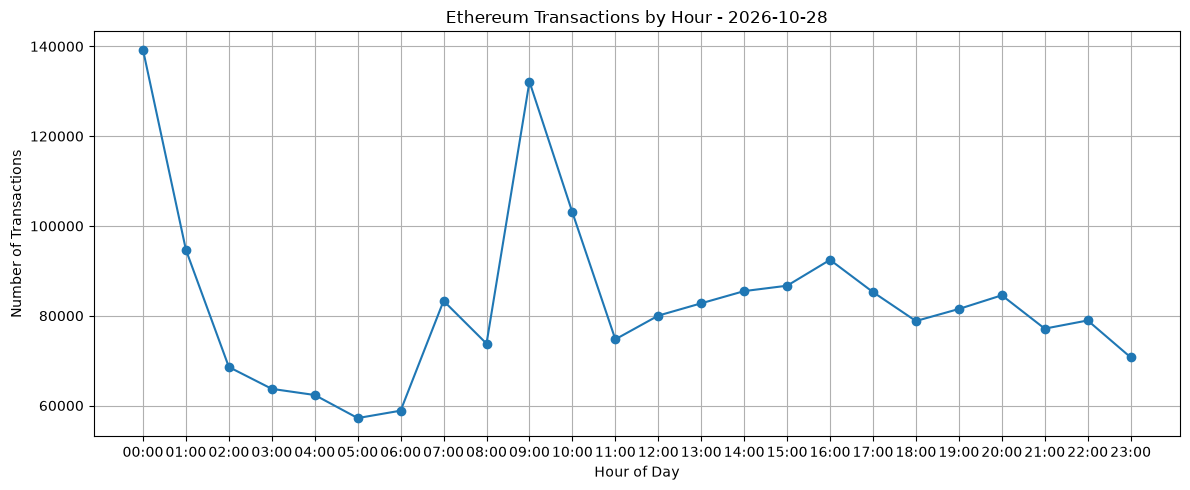

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_activity["hour"],
    hourly_activity["total_transactions"],
    marker="o"
)

plt.title("Ethereum Transactions by Hour - 2026-10-28")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24), [f"{h:02d}:00" for h in range(24)])
plt.xticks(range(24))
plt.grid(True)

plt.tight_layout()
plt.show()

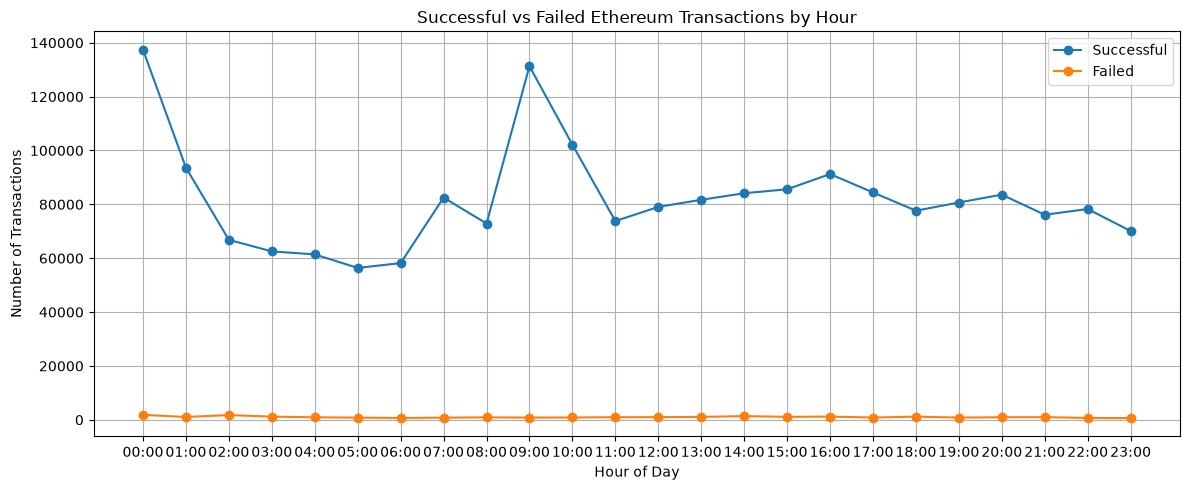

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_activity["hour"],
    hourly_activity["successful_transactions"],
    marker="o",
    label="Successful"
)

plt.plot(
    hourly_activity["hour"],
    hourly_activity["failed_transactions"],
    marker="o",
    label="Failed"
)

plt.title("Successful vs Failed Ethereum Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24), [f"{h:02d}:00" for h in range(24)])
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

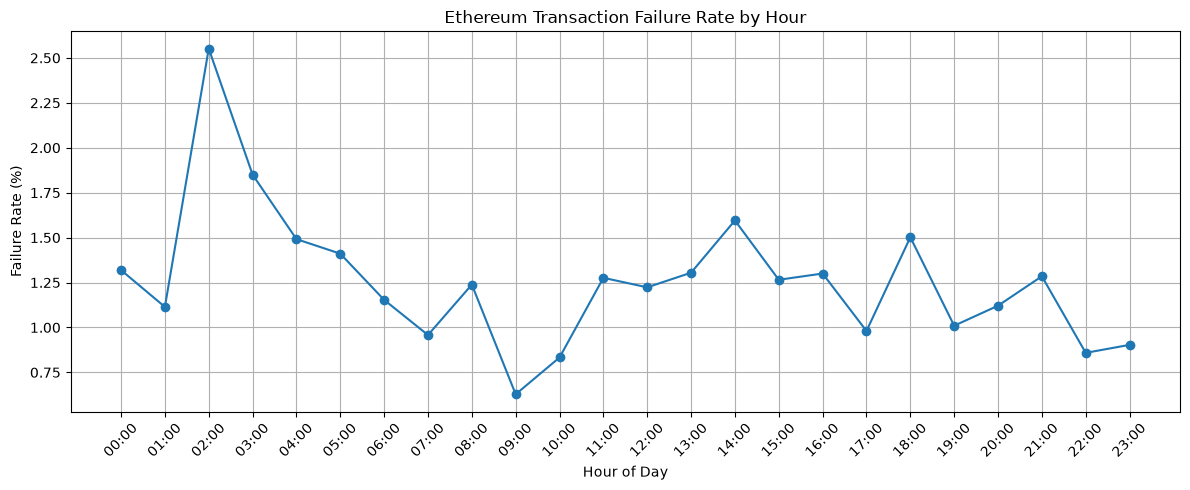

In [14]:
hourly_activity["failure_rate"] = (
    hourly_activity["failed_transactions"]
    / hourly_activity["total_transactions"]
) * 100

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_activity["hour"],
    hourly_activity["failure_rate"],
    marker="o"
)

plt.title("Ethereum Transaction Failure Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Failure Rate (%)")
plt.xticks(range(24), [f"{h:02d}:00" for h in range(24)], rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
print("Highest failure rate:")
display(
    hourly_activity.nlargest(3, "failure_rate")[
        ["hour", "total_transactions", "failed_transactions", "failure_rate"]
    ]
)

print("Lowest failure rate:")
display(
    hourly_activity.nsmallest(3, "failure_rate")[
        ["hour", "total_transactions", "failed_transactions", "failure_rate"]
    ]
)

Highest failure rate:


,hour,total_transactions,failed_transactions,failure_rate
2,2,68581,1750,2.551727
3,3,63719,1179,1.850312
14,14,85492,1364,1.595471


Lowest failure rate:


,hour,total_transactions,failed_transactions,failure_rate
9,9,132144,830,0.628103
10,10,103011,858,0.832921
22,22,78955,678,0.858717


In [16]:
gas_analysis = con.execute("""
    SELECT
        receipt_status,
        COUNT(*) AS total_transactions,

        ROUND(
            AVG(receipt_gas_used), 2
        ) AS avg_gas_used,

        ROUND(
            AVG(receipt_effective_gas_price) / 1e9, 4
        ) AS avg_gas_price_gwei,

        ROUND(
            SUM(
                CAST(receipt_gas_used AS DOUBLE)
                * CAST(receipt_effective_gas_price AS DOUBLE)
            ) / 1e18, 4
        ) AS approx_total_gas_fees_eth

    FROM read_parquet(?)
    GROUP BY receipt_status
    ORDER BY receipt_status
""", [file_path]).fetchdf()

gas_analysis

,receipt_status,total_transactions,avg_gas_used,avg_gas_price_gwei,approx_total_gas_fees_eth
0,0,24412,144501.51,0.4794,1.2745
1,1,1971694,108875.65,0.6166,109.1463


In [17]:
fee_per_transaction = con.execute("""
    SELECT
        receipt_status,
        COUNT(*) AS total_transactions,

        ROUND(
            AVG(
                CAST(receipt_gas_used AS DOUBLE)
                * CAST(receipt_effective_gas_price AS DOUBLE)
                / 1e18
            ), 8
        ) AS avg_fee_per_transaction_eth

    FROM read_parquet(?)
    GROUP BY receipt_status
    ORDER BY receipt_status
""", [file_path]).fetchdf()

fee_per_transaction

,receipt_status,total_transactions,avg_fee_per_transaction_eth
0,0,24412,0.000052
1,1,1971694,0.000055


In [18]:
type_analysis = con.execute("""
    SELECT
        transaction_type,
        COUNT(*) AS total_transactions,
        ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4)
            AS avg_gas_price_gwei,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions
    FROM read_parquet(?)
    GROUP BY transaction_type
    ORDER BY total_transactions DESC
""", [file_path]).fetchdf()

type_analysis

,transaction_type,total_transactions,avg_gas_used,avg_gas_price_gwei,failed_transactions
0,2,1528571,125031.81,0.6851,18925
1,0,424874,41678.60,0.3586,4855
2,4,25668,290655.02,0.2472,627
3,3,16498,107412.39,1.2941,0
4,1,495,275281.47,0.4233,5


In [19]:
type_analysis = con.execute("""
    SELECT
        transaction_type,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions,
        ROUND(
            AVG(receipt_gas_used), 2
        ) AS avg_gas_used
    FROM read_parquet(?)
    GROUP BY transaction_type
    ORDER BY transaction_type
""", [file_path]).fetchdf()

print(type_analysis.to_string(index=False))

 transaction_type  total_transactions  failed_transactions  avg_gas_used
                0              424874                 4855      41678.60
                1                 495                    5     275281.47
                2             1528571                18925     125031.81
                3               16498                    0     107412.39
                4               25668                  627     290655.02


In [20]:
failure_by_type = con.execute("""
    SELECT
        transaction_type,
        COUNT(*) AS total_transactions,

        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE receipt_status = 0
            ) / COUNT(*), 3
        ) AS failure_rate

    FROM read_parquet(?)
    GROUP BY transaction_type
    ORDER BY failure_rate DESC
""", [file_path]).fetchdf()

failure_by_type

,transaction_type,total_transactions,failed_transactions,failure_rate
0,4,25668,627,2.443
1,2,1528571,18925,1.238
2,0,424874,4855,1.143
3,1,495,5,1.010
4,3,16498,0,0.000


In [22]:
import subprocess

result = subprocess.run(
    ["py", "-3.13", "-c",
     "import numpy; numpy.show_runtime()"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

[{'numpy_version': '2.3.5',
  'python': '3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 '
            '64 bit (AMD64)]',
  'uname': uname_result(system='Windows', node='DESKTOP-9IPQ098', release='10', version='10.0.19042', machine='AMD64')},
 {'simd_extensions': {'baseline': ['SSE', 'SSE2', 'SSE3'],
                      'found': ['SSSE3', 'SSE41'],
                      'not_found': ['POPCNT',
                                    'SSE42',
                                    'AVX',
                                    'F16C',
                                    'FMA3',
                                    'AVX2',
                                    'AVX512F',
                                    'AVX512CD',
                                    'AVX512_SKX',
                                    'AVX512_CLX',
                                    'AVX512_CNL',
                                    'AVX512_ICL']}},
 {'ignore_floating_point_errors_in_matmul': False},
 {'architectur

In [23]:
print(
    con.execute("SELECT 1 + 1 AS test").fetchdf()
)

   test
0     2


In [24]:
con.execute("""
    SELECT
        extension_name,
        installed,
        loaded,
        install_mode
    FROM duckdb_extensions()
    WHERE extension_name = 'httpfs'
""").fetchdf()

,extension_name,installed,loaded,install_mode
0,httpfs,True,False,REPOSITORY


In [25]:
from pathlib import Path

extension_path = (
    Path.home()
    / ".duckdb"
    / "extensions"
    / "v2.0.0"
    / "windows_amd64"
    / "httpfs.duckdb_extension"
)

print("File exists:", extension_path.exists())

if extension_path.exists():
    print("File size:", extension_path.stat().st_size, "bytes")

File exists: True
File size: 52750870 bytes
